# Axe 10 : les profils financiers des entreprises

L'idée : regrouper les comptes des entreprises qui **se ressemblent financièrement**, **sans utiliser l'étiquette « faillite »**. Ensuite seulement, on regarde dans quels groupes la faillite (dans les 36 mois) est la plus fréquente. Si les groupes trouvés « à l'aveugle » séparent bien les entreprises fragiles, c'est que les ratios portent un vrai signal.

Méthodes du cours : **ACP** et **t-SNE** (transformation, TP4), **k-means**, **mélange gaussien** et **DBSCAN** (clustering, TP2), avec la **silhouette** et la méthode du coude pour choisir le nombre de groupes, et l'interprétation des centres en z-score comme pour les voitures du TP2.

### Lexique

| Terme | En clair |
|---|---|
| **ACP** | Résume beaucoup de variables liées en quelques axes (composantes) qui gardent le plus d'information (variance). |
| **k-means** | Range les points en k groupes autour de k centres ; chaque point va au centre le plus proche. |
| **Mélange gaussien (GMM)** | Comme k-means, mais chaque groupe est une « cloche » qui peut être allongée, et chaque point a une **probabilité** d'appartenir à chaque groupe. |
| **DBSCAN** | Groupe les points situés dans des zones denses ; les points isolés sont classés comme **bruit**. |
| **Silhouette** | Pour chaque point : est-il plus proche de son groupe que du groupe voisin ? De −1 à 1, plus c'est haut, plus les groupes sont nets. |
| **Inertie** | La somme des distances des points à leur centre. Elle baisse toujours quand k augmente : on cherche le coude. |
| **Log signé (symlog)** | Comme un logarithme, mais qui marche aussi pour les valeurs négatives : il resserre les très grandes valeurs. |

### Les décisions

| Sujet | Décision | Qui |
|---|---|---|
| Variables | Les **13 ratios** du fichier (pas les montants en euros, qui mesurent la taille, pas le profil). Le BFR en % du chiffre d'affaires est enlevé : il est identique au BFR en jours (corrélation 1,00). | Luka |
| Valeurs manquantes | On garde les exercices où **les 13 ratios sont remplis** (environ 57 %), sans rien inventer (pas d'imputation). On vérifie le biais. | Luka |
| Mise à l'échelle | **Log signé** puis **centrage-réduction** : les ratios sont très étalés même après la winsorisation (ex. liquidité jusqu'à 32 000 %). | Luka |
| Échantillon | **Un exercice tiré au hasard par entreprise**, pour qu'une entreprise avec 8 exercices ne pèse pas 8 fois plus. Puis 200 000 entreprises pour apprendre les groupes (k-means, GMM), moins pour DBSCAN et t-SNE (trop lents). Les groupes sont ensuite appliqués à **tous** les exercices complets. | Luka |
| Nombre de groupes | **k = 4**. Les mesures ne sont pas d'accord (silhouette maximale à k = 2, coude de l'inertie à k = 5) : d'après la fiche, il n'y a pas de groupes nets, on choisit selon l'usage. k = 4 a une meilleure silhouette que k = 3 et k = 5, et ses groupes séparent bien le risque de faillite (de 1,3 % à 6,8 %). Les noms des profils (section 5) sont des propositions. | Luka |

## 1. Chargement

In [1]:
import sys
sys.path.append("../../scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from data_utils import PROCESSED, NAF_SECTION_NOMS, free_memory, mem
import graphe_utils as gu   # pour les couleurs et le style des graphiques

DASH = PROCESSED.parent / "dashboard"
pd.set_option("display.max_columns", 30)
RATIOS = ["taux_d_endettement", "ratio_de_liquidite", "ratio_de_vetuste", "autonomie_financiere",
          "couverture_des_interets", "caf_sur_ca", "capacite_de_remboursement", "marge_ebe",
          "resultat_courant_avant_impots_sur_ca", "poids_bfr_exploitation_sur_ca_jours",
          "rotation_des_stocks_jours", "credit_clients_jours", "credit_fournisseurs_jours"]
COURTS = {"taux_d_endettement": "endettement", "ratio_de_liquidite": "liquidité", "ratio_de_vetuste": "vétusté",
          "autonomie_financiere": "autonomie fin.", "couverture_des_interets": "couverture intérêts",
          "caf_sur_ca": "CAF / CA", "capacite_de_remboursement": "capacité rembours.", "marge_ebe": "marge EBE",
          "resultat_courant_avant_impots_sur_ca": "résultat courant / CA",
          "poids_bfr_exploitation_sur_ca_jours": "BFR (jours)", "rotation_des_stocks_jours": "stocks (jours)",
          "credit_clients_jours": "crédit clients (j)", "credit_fournisseurs_jours": "crédit fournisseurs (j)"}

p = pd.read_parquet(PROCESSED / "panel_exercices.parquet",
                    columns=["siren", "date_cloture_exercice", *RATIOS, "chiffre_d_affaires", "faillite_36_mois",
                             "naf_section", "cj_famille", "age_ans"])
complet = p[RATIOS].notna().all(axis=1)
print(f"exercices : {len(p):,} | complets : {complet.sum():,} ({complet.mean():.1%})".replace(",", " "))
print(f"faillite dans les 36 mois : {p.loc[complet, 'faillite_36_mois'].mean():.2%} (complets)"
      f" contre {p.loc[~complet, 'faillite_36_mois'].mean():.2%} (incomplets) | {mem()}")
p = p[complet].reset_index(drop=True)
free_memory()

exercices : 5 057 975 | complets : 2 904 735 (57.4%)
faillite dans les 36 mois : 2.08% (complets) contre 1.67% (incomplets) | process : 1.60 Go | disponible : 5.24 Go


'process : 0.65 Go | disponible : 6.06 Go'

### Observations

- **2 904 735 exercices** sur 5 057 975 ont les 13 ratios remplis (57,4 %).
- Le biais est faible mais existe : il y a un peu **plus de faillites** parmi les exercices complets (2,08 %) que parmi les incomplets (1,67 %). Il faudra s'en souvenir : les profils décrivent les entreprises qui publient des comptes détaillés.

## 2. Préparation

In [2]:
def symlog(x):
    return np.sign(x) * np.log1p(np.abs(x))

# Un exercice tiré au hasard par entreprise
un_par_entreprise = p.sample(frac=1, random_state=0).drop_duplicates("siren")
print("entreprises :", len(un_par_entreprise))
scaler = StandardScaler().fit(symlog(un_par_entreprise[RATIOS]))
transforme = lambda df: scaler.transform(symlog(df[RATIOS]))
X_ent = transforme(un_par_entreprise)
echant = np.random.default_rng(0).choice(len(X_ent), 200_000, replace=False)
X = X_ent[echant]
pd.DataFrame({"avant (médiane)": un_par_entreprise[RATIOS].median(),
              "avant (max)": un_par_entreprise[RATIOS].max(),
              "après (écart-type)": X.std(axis=0)}).rename(index=COURTS).round(1)

entreprises : 914551


,avant (médiane),avant (max),après (écart-type)
endettement,20.000000,4597.899902,1.0
liquidité,179.800003,31913.099609,1.0
vétusté,41.299999,100.000000,1.0
autonomie fin.,33.099998,122.500000,1.0
couverture intérêts,0.300000,346.899994,1.0
CAF / CA,5.900000,672.799988,1.0
capacité rembours.,0.300000,111.500000,1.0
marge EBE,6.400000,94.300003,1.0
résultat courant / CA,3.900000,618.299988,1.0
BFR (jours),26.600000,9908.099609,1.0


### Observations

- On garde **914 551 entreprises** (un exercice chacune). Les ratios sont très étalés : la médiane de la liquidité est de 180 %, mais le maximum atteint 31 913 %. Après le log signé et la centrage-réduction, tous les ratios ont un écart-type de 1.

## 3. ACP : les ratios se résument-ils à quelques axes ?

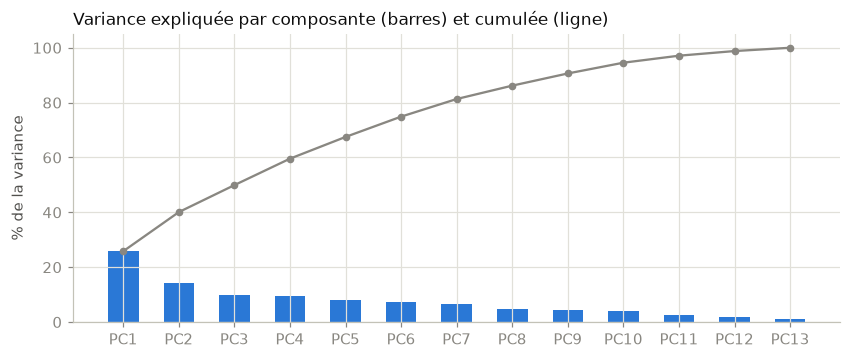

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
variance cumulée (%),25.799999,40.099998,49.900002,59.599998,67.5,74.900002,81.300003,86.199997


In [3]:
pca = PCA().fit(X)
var = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i}" for i in range(1, len(RATIOS) + 1)])
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(var.index, 100 * var.values, color=gu.BLEU, width=0.55)
ax.plot(var.index, 100 * var.cumsum().values, color=gu.GRIS, marker="o", ms=4, lw=1.5)
ax.set_ylabel("% de la variance")
ax.set_title("Variance expliquée par composante (barres) et cumulée (ligne)", loc="left", fontsize=11, color=gu.TITRE)
plt.show()
(100 * var.cumsum()).round(1).head(8).to_frame("variance cumulée (%)").T

### Observations

- La première composante ne garde que **26 %** de la variance, et il faut **6 composantes** pour dépasser 70 %. Les 13 ratios ne se résument donc **pas** à 2 ou 3 axes : ils portent des informations assez différentes.

In [4]:
# Les ratios qui portent les 3 premiers axes
charges = pd.DataFrame(pca.components_[:3].T, index=[COURTS[r] for r in RATIOS], columns=["PC1", "PC2", "PC3"])
charges.round(2).sort_values("PC1")

,PC1,PC2,PC3
crédit fournisseurs (j),-0.04,0.23,0.58
stocks (jours),-0.02,0.21,-0.05
crédit clients (j),0.04,0.44,0.35
vétusté,0.06,-0.18,-0.02
BFR (jours),0.08,0.62,0.05
liquidité,0.16,0.45,-0.27
autonomie fin.,0.24,0.13,-0.46
endettement,0.27,0.14,-0.34
couverture intérêts,0.29,-0.12,0.28
capacité rembours.,0.32,-0.07,0.16


### Observations

- **PC1 = la rentabilité** : CAF / CA (0,48), marge d'EBE (0,46), résultat courant (0,45), puis capacité de remboursement et couverture des intérêts.
- **PC2 = le cycle d'exploitation** : BFR en jours (0,62), liquidité (0,45), crédit clients (0,44). Elle oppose les entreprises payées comptant à celles qui font crédit à leurs clients.
- **PC3 = la structure financière** : crédit fournisseurs (0,58) d'un côté, autonomie financière (−0,46) et endettement (−0,34) de l'autre.

## 4. k-means : combien de groupes ?

On essaie k = 2 à 10. Pour chaque k : l'**inertie** (méthode du coude) et la **silhouette** (calculée sur 10 000 points, elle est trop lente sur 200 000).

coude de l'inertie : k = 5.0


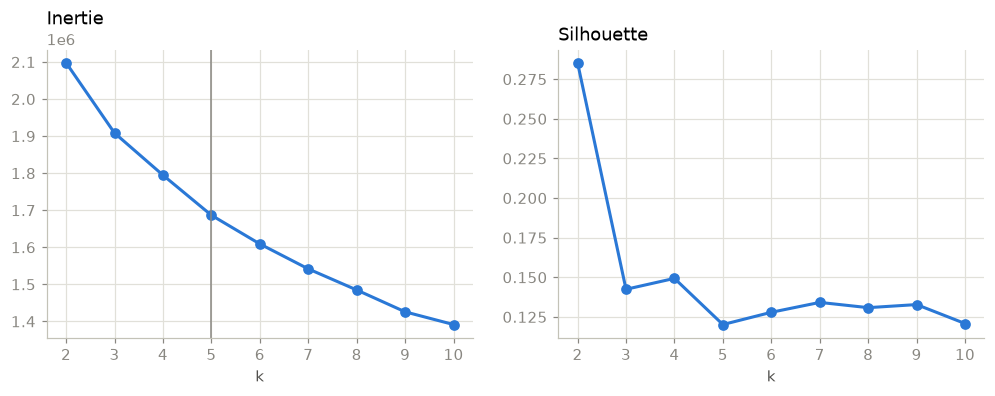

,inertie,silhouette,gain d'inertie (%)
k,,,
2,2097958.500,0.285,NaN
3,1908390.375,0.142,9.036
4,1794724.250,0.149,5.956
5,1686558.250,0.120,6.027
6,1609066.500,0.128,4.595
7,1541712.125,0.134,4.186
8,1484803.250,0.131,3.691
9,1425788.250,0.133,3.975
10,1391497.875,0.121,2.405


In [5]:
sous = np.random.default_rng(1).choice(len(X), 10_000, replace=False)
lignes = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=5, random_state=0).fit(X)
    lignes.append({"k": k, "inertie": km.inertia_, "silhouette": silhouette_score(X[sous], km.labels_[sous])})
choix_k = pd.DataFrame(lignes).set_index("k")
choix_k["gain d'inertie (%)"] = -100 * choix_k["inertie"].pct_change()
coude_k = gu.coude(choix_k.index, choix_k["inertie"])
print("coude de l'inertie : k =", coude_k)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(choix_k.index, choix_k["inertie"], color=gu.BLEU, marker="o", lw=2); axes[0].set_title("Inertie", loc="left")
axes[0].axvline(coude_k, color=gu.GRIS, lw=1)
axes[1].plot(choix_k.index, choix_k["silhouette"], color=gu.BLEU, marker="o", lw=2); axes[1].set_title("Silhouette", loc="left")
for ax in axes: ax.set_xlabel("k")
plt.show()
choix_k.round(3)

### Observations

- La **silhouette** est la plus haute à **k = 2** (0,29), puis tombe autour de 0,12 à 0,15. Ces valeurs sont **faibles** : les groupes ne sont pas bien séparés.
- L'inertie n'a **pas de coude franc**. La méthode Kneedle donne k = 5, mais chaque groupe ajouté ne fait gagner que 4 à 6 % d'inertie.
- Comme pour les voitures du TP2, les mesures ne sont pas d'accord : **il n'y a pas de groupes nets**, on choisit k selon l'usage.

In [6]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X)
# On applique les groupes à TOUS les exercices complets
p["profil"] = km.predict(transforme(p)) + 1
taille_faillite = p.groupby("profil").agg(exercices=("siren", "size"), entreprises=("siren", "nunique"),
                                          taux_faillite=("faillite_36_mois", "mean"))
taille_faillite["taux_faillite"] = 100 * taille_faillite["taux_faillite"]
taille_faillite["risque vs moyenne"] = taille_faillite["taux_faillite"] / (100 * p["faillite_36_mois"].mean())
taille_faillite.round(2)

,exercices,entreprises,taux_faillite,risque vs moyenne
profil,,,,
1,771290,372920,1.55,0.75
2,1511106,562228,1.31,0.63
3,228955,140481,6.84,3.29
4,393384,242878,3.29,1.58


### Observations

- Les 4 profils séparent bien le **risque de faillite**, alors que l'étiquette n'a pas servi à les construire : de **1,31 %** (profil 2) à **6,84 %** (profil 3). Le profil 3 a un risque **3,3 fois** plus élevé que la moyenne.

## 5. Interpréter les groupes

Comme au TP2 : on regarde les **centres en z-score** (combien d'écarts-types au-dessus ou en dessous de la moyenne), puis les **médianes réelles** des ratios dans chaque groupe.

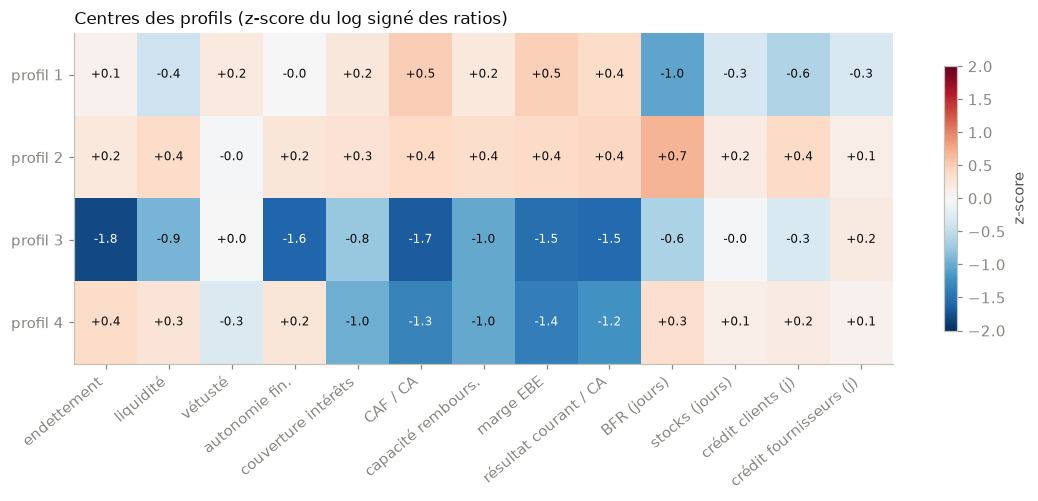

In [7]:
centres = pd.DataFrame(km.cluster_centers_, columns=[COURTS[r] for r in RATIOS], index=range(1, K + 1))
fig, ax = plt.subplots(figsize=(12, 0.6 * K + 1.5))
im = ax.imshow(centres.to_numpy(), cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(RATIOS)), centres.columns, rotation=40, ha="right")
ax.set_yticks(range(K), [f"profil {i}" for i in centres.index])
for i in range(K):
    for j in range(len(RATIOS)):
        ax.text(j, i, f"{centres.iat[i, j]:+.1f}", ha="center", va="center", fontsize=8,
                color="white" if abs(centres.iat[i, j]) > 1.2 else gu.TITRE)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="z-score")
ax.set_title("Centres des profils (z-score du log signé des ratios)", loc="left", fontsize=11, color=gu.TITRE)
plt.show()

In [8]:
medianes = p.groupby("profil")[RATIOS].median().rename(columns=COURTS)
medianes.insert(0, "faillite (%)", taille_faillite["taux_faillite"])
medianes.round(1)

,faillite (%),endettement,liquidité,vétusté,autonomie fin.,couverture intérêts,CAF / CA,capacité rembours.,marge EBE,résultat courant / CA,BFR (jours),stocks (jours),crédit clients (j),crédit fournisseurs (j)
profil,,,,,,,,,,,,,,
1,1.5,26.000000,122.300003,46.200001,29.700001,0.9,11.1,0.5,11.8,7.2,-39.299999,0.0,1.800000,29.600000
2,1.3,24.299999,236.500000,33.299999,40.599998,1.5,7.3,1.1,8.1,6.0,72.400002,5.3,50.000000,49.400002
3,6.8,-127.000000,68.300003,40.200001,-10.400000,-0.7,-13.7,-1.0,-12.3,-18.5,-24.400000,1.5,10.700000,57.500000
4,3.3,38.700001,196.100006,26.799999,33.799999,-1.5,-5.5,-1.0,-6.4,-7.5,64.300003,2.7,40.299999,47.099998


### Observations

Lecture des profils (les noms sont des **propositions**) :
- **Profil 1 – « rentables, payées comptant »** (faillite 1,5 %) : bonne rentabilité (marge d'EBE 11,8 %), clients qui paient presque tout de suite (crédit clients médian de 2 jours), BFR négatif. Beaucoup d'hébergement-restauration (18,6 %) et d'immobilier.
- **Profil 2 – « installées et solides »** (1,3 %, le plus faible) : rentables, bonne liquidité (237 %) et autonomie (41 %), clients payés à 50 jours. Ce sont les plus grandes (CA médian 886 k€) et les plus anciennes (14 ans).
- **Profil 3 – « en perte, capitaux propres négatifs »** (6,8 %, le plus risqué) : pertes (marge d'EBE −12 %, résultat courant −19 %), **autonomie financière négative** (−10 %, les capitaux propres sont passés sous zéro), faible liquidité (68 %). Plutôt jeunes (7,8 ans) et petites (CA médian 147 k€).
- **Profil 4 – « en perte, mais encore solides »** (3,3 %) : pertes (marge d'EBE −6 %), mais une autonomie (34 %) et une liquidité (196 %) correctes. Le risque est 2,5 fois celui du profil 2.

In [9]:
# Validation avec des variables NON utilisées pour former les groupes (comme au TP2)
sect = pd.crosstab(p["naf_section"].astype("string").map(lambda l: f"{l} {NAF_SECTION_NOMS.get(l, '?')}"),
                   p["profil"], normalize="columns").mul(100)
sect.loc[sect.max(axis=1).sort_values(ascending=False).index[:10]].round(1)

profil,1,2,3,4
naf_section,,,,
G Commerce,14.3,25.2,21.8,21.0
"I Hébergement, restauration",18.6,3.3,15.9,7.0
F Construction,9.8,16.0,8.6,13.0
"M Activités spécialisées, scientifiques",10.2,12.4,8.2,13.3
C Industrie manufacturière,4.5,10.6,6.4,8.7
L Immobilier,10.3,4.7,9.1,5.4
"K Finance, assurance",5.8,6.4,2.8,8.1
N Services administratifs,5.5,5.6,5.5,5.6
S Autres services,5.1,1.3,5.1,2.5


### Observations

- Les profils ne correspondent pas à des secteurs, mais certains secteurs pèsent plus dans certains profils : l'**hébergement-restauration** dans les profils 1 (18,6 %) et 3 (15,9 %), l'**industrie** et la **construction** dans le profil 2.

In [10]:
p.groupby("profil").agg(**{"âge médian (ans)": ("age_ans", "median"),
                           "CA médian (k€)": ("chiffre_d_affaires", lambda s: s.median() / 1000)}).round(1)

,âge médian (ans),CA médian (k€)
profil,,
1,7.8,186.600006
2,14.2,886.200012
3,7.8,147.000000
4,14.1,277.200012


### Observations

- Les profils 1 et 3 sont plus **jeunes** (7,8 ans) et plus **petits** (CA médian 150 à 190 k€) que les profils 2 et 4 (14 ans, 280 à 890 k€).

## 6. Mélange gaussien : les mêmes groupes ?

On ajuste un mélange gaussien avec le même nombre de groupes, et on compare avec k-means (ARI). Le mélange donne aussi une **probabilité** d'appartenance : on regarde la part des entreprises **hésitantes** (aucun groupe à plus de 60 %).

In [11]:
gmm = GaussianMixture(n_components=K, covariance_type="full", random_state=0, n_init=2).fit(X)
lab_gmm = gmm.predict(X)
proba = gmm.predict_proba(X).max(axis=1)
print("ARI k-means / mélange gaussien :", round(adjusted_rand_score(km.labels_, lab_gmm), 3))
print(f"entreprises hésitantes (probabilité max < 0,6) : {np.mean(proba < 0.6):.1%}")
fail_ech = un_par_entreprise["faillite_36_mois"].to_numpy()[echant]
pd.DataFrame({"entreprises": pd.Series(lab_gmm + 1).value_counts().sort_index(),
              "faillite (%)": pd.Series(100 * fail_ech).groupby(lab_gmm + 1).mean()}).round(2)

ARI k-means / mélange gaussien : 0.305
entreprises hésitantes (probabilité max < 0,6) : 2.2%


,entreprises,faillite (%)
1,55431,2.07
2,55632,1.98
3,33561,7.30
4,55376,3.45


### Observations

- Le mélange gaussien trouve des groupes **assez différents** de k-means (ARI 0,31). C'est logique avec des groupes peu séparés : chaque méthode découpe le nuage à sa façon.
- Il est pourtant très **sûr de lui** : seulement 2,2 % des entreprises hésitent entre deux groupes.
- On retrouve un groupe à **risque élevé** (7,3 % de faillite) et trois groupes plus proches (2,0 % à 3,5 %).

## 7. DBSCAN : qui est « bruit » ?

DBSCAN est lent : on le lance sur 20 000 entreprises, dans l'espace des 5 premières composantes de l'ACP. Le rayon `eps` est choisi avec la **courbe des distances au 10e voisin** (comme au TP2) : on prend le coude.

In [12]:
idx_db = np.random.default_rng(2).choice(len(X), 20_000, replace=False)
Z = pca.transform(X[idx_db])[:, :5]
dist = np.sort(NearestNeighbors(n_neighbors=10).fit(Z).kneighbors(Z)[0][:, -1])
eps = float(dist[int(gu.coude(np.arange(len(dist)), dist))])
db = DBSCAN(eps=eps, min_samples=10).fit(Z)
bruit = db.labels_ == -1
print(f"eps = {eps:.2f} | groupes : {len(set(db.labels_)) - (1 if bruit.any() else 0)} | bruit : {bruit.mean():.1%}")
ech_db = un_par_entreprise.iloc[echant[idx_db]]
ramene = pd.read_parquet(PROCESSED / "ratios_clean.parquet", columns=["siren", "date_cloture_exercice"] +
                         [r + "_ramene" for r in RATIOS])
ech_db = ech_db.merge(ramene, on=["siren", "date_cloture_exercice"], how="left")
del ramene
free_memory()
ech_db["au moins une valeur ramenée"] = ech_db[[r + "_ramene" for r in RATIOS]].any(axis=1)
pd.DataFrame({"faillite (%)": [100 * ech_db.loc[bruit, "faillite_36_mois"].mean(), 100 * ech_db.loc[~bruit, "faillite_36_mois"].mean()],
              "au moins une valeur ramenée (%)": [100 * ech_db.loc[bruit, "au moins une valeur ramenée"].mean(),
                                                   100 * ech_db.loc[~bruit, "au moins une valeur ramenée"].mean()]},
             index=["bruit", "dans un groupe"]).round(1)

eps = 1.15 | groupes : 1 | bruit : 3.6%


,faillite (%),au moins une valeur ramenée (%)
bruit,2.6,60.2
dans un groupe,3.4,6.5


### Observations

- DBSCAN ne trouve **qu'un seul grand groupe** et classe **3,6 %** des entreprises en **bruit** : il confirme qu'il n'y a pas de groupes nettement séparés, seulement un grand nuage dense.
- Les points de bruit ne font **pas plus faillite** (2,6 % contre 3,4 %). En revanche, **60 %** d'entre eux ont au moins une valeur **ramenée par la winsorisation**, contre 6,5 % des autres. Ça répond à une question posée au nettoyage : oui, les valeurs ramenées par la winsorisation se retrouvent souvent dans le « bruit ».

## 8. Voir les profils : ACP et t-SNE

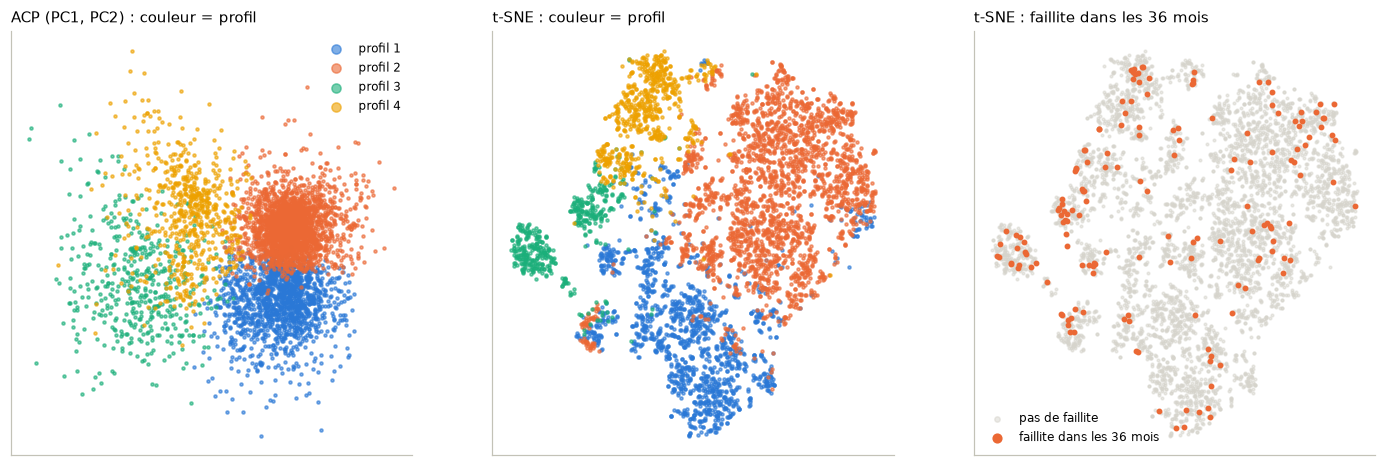

In [13]:
idx_vis = np.random.default_rng(3).choice(len(X), 5_000, replace=False)
P2 = pca.transform(X[idx_vis])[:, :2]
T2 = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(X[idx_vis])
lab_vis = km.labels_[idx_vis] + 1
fail_vis = fail_ech[idx_vis]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, coords, titre in [(axes[0], P2, "ACP (PC1, PC2)"), (axes[1], T2, "t-SNE")]:
    for k in range(1, K + 1):
        m = lab_vis == k
        ax.scatter(coords[m, 0], coords[m, 1], s=4, color=gu.COULEURS[(k - 1) % 8], alpha=0.6, label=f"profil {k}")
    ax.set_title(f"{titre} : couleur = profil", loc="left", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(frameon=False, markerscale=3, fontsize=8)
axes[2].scatter(T2[~fail_vis, 0], T2[~fail_vis, 1], s=3, color="#d6d4cc", alpha=0.5, label="pas de faillite")
axes[2].scatter(T2[fail_vis, 0], T2[fail_vis, 1], s=8, color=gu.COULEURS[1], label="faillite dans les 36 mois")
axes[2].set_title("t-SNE : faillite dans les 36 mois", loc="left", fontsize=10); axes[2].set_xticks([]); axes[2].set_yticks([])
axes[2].legend(frameon=False, markerscale=2, fontsize=8)
plt.show()

### Observations

- Sur l'ACP, les profils se chevauchent mais occupent chacun une zone. Le profil 3 (vert) est le plus étalé.
- Le t-SNE sépare mieux les profils, et le profil 3 forme un îlot à gauche.
- Sur la troisième carte, les **faillites** (en orange) sont plus nombreuses dans la zone du profil 3 et du profil 4 (en haut à gauche), mais on en trouve partout. Les ratios donnent un signal, pas une séparation nette.

## 9. Export pour le dashboard

In [14]:
resume = taille_faillite.join(medianes.drop(columns="faillite (%)")).reset_index()
resume.columns = [str(c) for c in resume.columns]
resume.to_parquet(DASH / "profils_resume.parquet", index=False)
centres.reset_index(names="profil").to_parquet(DASH / "profils_centres.parquet", index=False)
pd.DataFrame({"pc1": P2[:, 0], "pc2": P2[:, 1], "tsne_x": T2[:, 0], "tsne_y": T2[:, 1], "profil": lab_vis,
              "faillite_36_mois": fail_vis}).to_parquet(DASH / "profils_points.parquet", index=False)
choix_k.reset_index().to_parquet(DASH / "profils_choix_k.parquet", index=False)
pd.DataFrame({"composante": var.index, "variance": var.values}).to_parquet(DASH / "profils_acp_variance.parquet", index=False)
print("export : profils_resume, profils_centres, profils_points, profils_choix_k, profils_acp_variance")

export : profils_resume, profils_centres, profils_points, profils_choix_k, profils_acp_variance
